In [1]:
import numpy as np
import pylab as plt

In [2]:
# set constants
OMEGA_PERTURBATION_SQUARED = 0.5 # technically this has units of angular frequency
OMEGA_KEPLER_SQUARED = (2. * np.pi) ** 2 # orbital angular frequency squared in (rad / yr)^2 for a circular orbit at r = 1 a.u.
TIDE = np.diag([1., 1., -2.])

In [3]:
def a(r, t):
    return -OMEGA_KEPLER_SQUARED * r / np.linalg.norm(r) ** 3 \
           - 2. * OMEGA_PERTURBATION_SQUARED * (TIDE @ r)

In [4]:
def leapfrog_start(r, v, h):
    """
    ## notes:
    - convention: move position is 0.5 * h into the future
    """
    return r + v * 0.5 * h, v + 0.

def leapfrog_step(r, v, t, a, h):
    v_next = v + a(r, t) * h
    return r + v_next * h, v_next

def leapfrog(r, v, a, h, n):
    """
    ## notes:
    - returns two sets of times, one for the positions and one for the velocities
    """
    d = len(r)
    assert len(v) == d
    rs, vs, ts = np.zeros((n, d)), np.zeros((n, d)), h * np.arange(n)
    rr, vv = leapfrog_start(r, v, h)
    rs[0], vs[0] = rr, vv
    for i in range(1, n):
        rr, vv = leapfrog_step(rr, vv, ts[i], a, h)
        rs[i], vs[i] = rr, vv
    return rs, ts + 0.5 * h, vs, ts

In [5]:
h = 0.0001 # years
r0 = np.array([1.0, 0.0, 0.0]) # a.u.
foo = 0.0001 # radians
v0 = np.array([0.0, 2. * np.pi * np.cos(foo), 1.0]) # a.u. per year
rs, trs, vs, tvs = leapfrog(r0, v0, a, h, 2_000_000) # 200 years

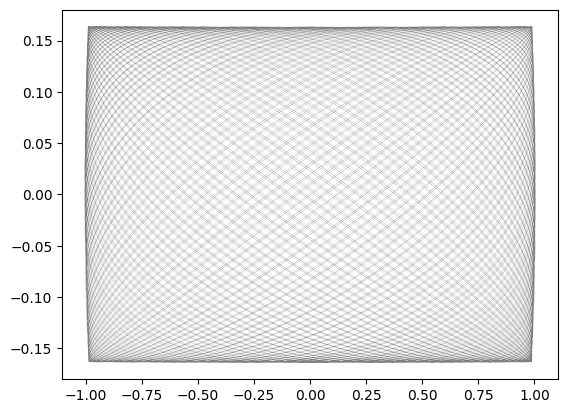

In [6]:
plt.plot(rs[:,0], rs[:, 2], "k-", alpha=0.5, lw=0.1)

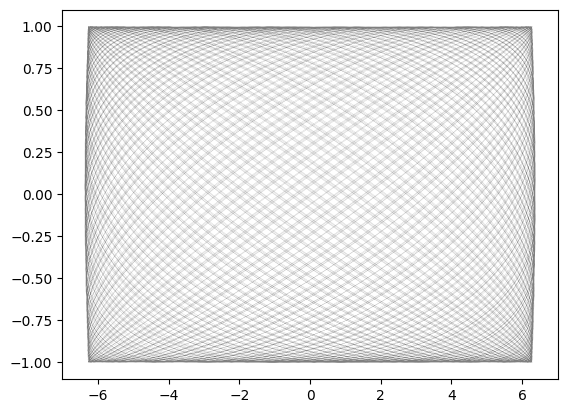

In [7]:
plt.plot(vs[:,0], vs[:, 2], "k-", alpha=0.5, lw=0.1)

In [8]:
def get_positive_zero_crossings(xs, ts):
    ii = (xs <= 0.) & (np.roll(xs, -1) > 0.)
    ii[-1] = False # the last entry can't be a crossing
    idxs = np.arange(len(rs))[ii]
    crossings = 1. * np.zeros_like(idxs)
    for j, i in enumerate(idxs):
        crossings[j] = ts[i] - xs[i] * (ts[i+1] - ts[i]) / (xs[i+1] - xs[i])
    return crossings

In [9]:
sos_times = get_positive_zero_crossings(rs[:, 2], trs) # z-axis!
print(sos_times)

[  1.02830128   2.05669159   3.08524084   4.11398481   5.14291727
   6.17199129   7.20112922   8.2302396    9.25923691  10.28806016
  11.31668601  12.34513373  13.37346092  14.40175103  15.4300955
  16.45857408  17.48723774  18.51609759  19.54512238  20.57424517
  21.60337776  22.63242981  23.66132848  24.69003412  25.71854879
  26.7469157   27.77520978  28.80352161  29.83193796  30.86052315
  31.88930521  32.9182697   33.94736274  34.97650258  36.00559732
  37.03456485  38.06335062  39.09193939  40.12035842  41.14867147
  42.17696503  43.20532979  44.23384115  45.26254303  46.2914383
  47.32048806  48.34961994  49.37874377  50.40777112  51.4366345
  52.46530189  53.4937836   54.52212993  55.55042023  56.57874588
  57.60719069  58.63581288  59.66463248  60.69362697  61.72273596
  62.75187424  63.78095025  64.80988593  65.83863365  66.86718637
  67.89557911  68.92388128  69.95218171  70.9805696   72.0091154
  73.03785562  74.06678485  75.09585683  76.1249944   77.15410614
  78.18310625 

In [10]:
# use the correct times with the correct quantities
sos_xs = np.interp(sos_times, trs, rs[:, 0])
sos_ys = np.interp(sos_times, trs, rs[:, 1])
sos_vxs = np.interp(sos_times, tvs, vs[:, 0])
sos_vys = np.interp(sos_times, tvs, vs[:, 1])
sos_rhos = np.sqrt(sos_xs ** 2 + sos_ys ** 2)
sos_vrhos = (sos_vxs * sos_xs + sos_vys * sos_ys) / sos_rhos

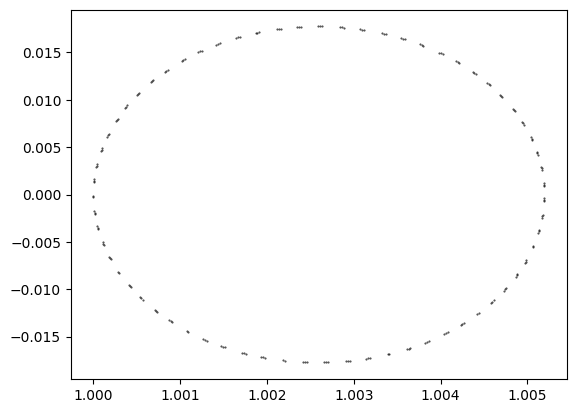

In [11]:
plt.scatter(sos_rhos, sos_vrhos, marker=".", c="k", s=1.0, alpha=0.75)

In [12]:
def plot_one_orbit(r0, v0, a=a, h=h):
    rs, trs, vs, tvs = leapfrog(r0, v0, a, h, 2_000_000) # 200 years
    sos_times = get_positive_zero_crossings(rs[:, 2], trs) # z-axis!
    sos_xs = np.interp(sos_times, trs, rs[:, 0])
    sos_ys = np.interp(sos_times, trs, rs[:, 1])
    sos_vxs = np.interp(sos_times, tvs, vs[:, 0])
    sos_vys = np.interp(sos_times, tvs, vs[:, 1])
    sos_rhos = np.sqrt(sos_xs ** 2 + sos_ys ** 2)
    sos_vrhos = (sos_vxs * sos_xs + sos_vys * sos_ys) / sos_rhos
    return plt.scatter(sos_rhos, sos_vrhos, marker=".", c="k", s=1.0, alpha=0.75)

In [ ]:
for vr0 in np.arange(0.65, 1.49, 0.10):
    print(f"working on {vr0:0.2f}")
    v0 = np.array([vr0, 2. * np.pi, 0.6]) # a.u. per year
    plot_one_orbit(r0, v0)

working on 0.65
working on 0.75
working on 0.85
working on 0.95
